# EDA de Home Credit

Igual que con ULB, antes de armar contextos queremos conocer la tabla.


Miramos: 
1) tasa de default
2) tipos de columnas
3) faltantes 
4) cardinalidad de las categóricas
5) anomalías (sobre todo `DAYS_EMPLOYED`)
6) qué variables muestran más señal 
7) duplicados.

## 0. Preparación

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

from tpf.data.loaders import load_home_credit
from tpf.data.splits import load_split, make_split, row_hashes, split_path
from tpf.paths import REPORTS

SEED = 0
FIG_DIR = REPORTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110
COLORES = {"no default": "tab:blue", "default": "tab:red"}

### Cargar y quedarnos solo con train

In [26]:
X_all, y_all = load_home_credit()

if split_path("home_credit", SEED).exists():
    parts = load_split("home_credit", SEED)
else:
    parts = make_split(y_all, SEED)

idx_train = parts["train"]
X = X_all.iloc[idx_train].reset_index(drop=True)
y = y_all.iloc[idx_train].reset_index(drop=True)
etiqueta = y.map({0: "no default", 1: "default"})  # nombre legible de cada clase

del X_all, y_all, parts  # se eliminan val y test

assert X.shape == (184_506, 120), X.shape
assert int(y.sum()) == 14_895, int(y.sum())
print(f"Train (semilla {SEED}): {X.shape[0]:,} filas x {X.shape[1]} columnas")

Train (semilla 0): 184,506 filas x 120 columnas


## 1. Tasa de default

Define cuántos positivos (clientes que no pagan) entran en un contexto.

In [27]:
n = len(y)
n_pos = int(y.sum())
n_neg = n - n_pos
pi = n_pos / n

balance = pd.DataFrame(
    {"filas": [n_neg, n_pos], "porcentaje": [100 * n_neg / n, 100 * pi]},
    index=["no default (0)", "default (1)"],
)
display(balance)

filas = []
for m in (1_000, 5_000, 10_000):
    filas.append(
        {
            "m (tamaño del contexto)": m,
            "defaults esperados (Uniform)": m * pi,
            "defaults en Balanced": min(n_pos, m // 2),
            "% de default en Balanced": 100 * min(n_pos, m // 2) / m,
            "¿Balanced queda capado?": "sí" if n_pos < m // 2 else "no",
        }
    )
tabla_contexto = pd.DataFrame(filas).set_index("m (tamaño del contexto)")
display(tabla_contexto)

,filas,porcentaje
no default (0),169611,91.927
default (1),14895,8.073


,defaults esperados (Uniform),defaults en Balanced,% de default en Balanced,¿Balanced queda capado?
m (tamaño del contexto),,,,
1000,80.729,500,50.000,no
5000,403.645,2500,50.000,no
10000,807.291,5000,50.000,no


Un modelo que siempre dice no default acierta 91,93% y detecta 0 de 14895 defaults.
Hay 11,4 clientes que pagan por cada uno que no paga.

## 2. Tipos de columnas

Los modelos tratan distinto a las numéricas y a las categóricas. El modelo TabPFN necesita el contexto con variables numéricas, y los modelos clásicos las convierte en one-hot. Es por esto que, este análisis es importante para confeccionar las dos vistas de los datos.

In [28]:
cols_cat = X.select_dtypes(exclude="number").columns.tolist()
cols_num = X.select_dtypes(include="number").columns.tolist()
cols_bin = [c for c in cols_num if X[c].dropna().nunique() <= 2]

print(f"Columnas numéricas:   {len(cols_num)} ({len(cols_bin)} binarias)")
print(f"Columnas categóricas: {len(cols_cat)}")
print("Categóricas:", cols_cat)

Columnas numéricas:   104 (32 binarias)
Columnas categóricas: 16
Categóricas: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


## 3. Valores faltantes

Este amálisis es importante porque TabPFN acepta faltantes, pero los modelos clásicos necesitan que se imputen.

In [29]:
pct_na = X.isna().mean().mul(100).sort_values(ascending=False)
mas_50 = pct_na[pct_na > 50]
mas_90 = pct_na[pct_na > 90]

print(f"Columnas con algún faltante: {int((pct_na > 0).sum())} de {X.shape[1]}")
print(f"Columnas con más de 50% de faltantes: {len(mas_50)}")
print(f"Columnas con más de 90% de faltantes: {len(mas_90)}")
print(f"Filas con al menos un faltante: {100 * X.isna().any(axis=1).mean():.1f}%")
sufijos = ("_AVG", "_MODE", "_MEDI")
print(
    f"De las columnas con >50% faltante, {sum(c.endswith(sufijos) for c in mas_50.index)} "
    f"terminan en _AVG/_MODE/_MEDI (datos de la vivienda)"
)

display(pct_na.head(15).to_frame("% faltante"))

Columnas con algún faltante: 66 de 120
Columnas con más de 50% de faltantes: 41
Columnas con más de 90% de faltantes: 0
Filas con al menos un faltante: 97.2%
De las columnas con >50% faltante, 39 terminan en _AVG/_MODE/_MEDI (datos de la vivienda)


,% faltante
COMMONAREA_AVG,69.815
COMMONAREA_MODE,69.815
COMMONAREA_MEDI,69.815
NONLIVINGAPARTMENTS_AVG,69.384
NONLIVINGAPARTMENTS_MODE,69.384
NONLIVINGAPARTMENTS_MEDI,69.384
LIVINGAPARTMENTS_AVG,68.303
LIVINGAPARTMENTS_MODE,68.303
LIVINGAPARTMENTS_MEDI,68.303
FONDKAPREMONT_MODE,68.272


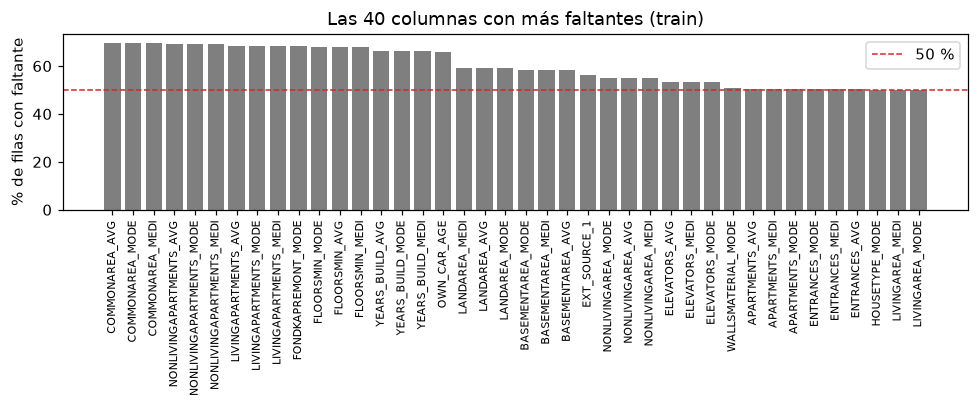

In [30]:
top = pct_na.head(40)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(range(len(top)), top.values, color="tab:gray")
ax.axhline(50, color="tab:red", ls="--", lw=1, label="50 %")
ax.set_xticks(range(len(top)))
ax.set_xticklabels(top.index, rotation=90, fontsize=7)
ax.set_ylabel("% de filas con faltante")
ax.set_title("Las 40 columnas con más faltantes (train)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_eda_hc_faltantes.png")
plt.show()

Es importante saber si los faltantes aportan o no información, por lo que nos interesa saber la tasa de default de cuando el dato falta contra cuando no falta. Que estos valores difieran significaría que  el faltante lleva información y no se deberia tratar como los demás. 

In [31]:
filas = []
for c in pct_na[pct_na >= 1].index:
    falta = X[c].isna()
    if falta.sum() < 200 or (~falta).sum() < 200:  # excluimos grupos muy chicos
        continue
    filas.append(
        {
            "columna": c,
            "% faltante": pct_na[c],
            "default si falta (%)": 100 * y[falta].mean(),
            "default si está (%)": 100 * y[~falta].mean(),
        }
    )
info = pd.DataFrame(filas)
info["diferencia (puntos)"] = info["default si falta (%)"] - info["default si está (%)"]
info = info.reindex(info["diferencia (puntos)"].abs().sort_values(ascending=False).index)
display(info.head(10).set_index("columna"))

,% faltante,default si falta (%),default si está (%),diferencia (puntos)
columna,,,,
AMT_REQ_CREDIT_BUREAU_QRT,13.552,10.522,7.689,2.833
AMT_REQ_CREDIT_BUREAU_WEEK,13.552,10.522,7.689,2.833
AMT_REQ_CREDIT_BUREAU_HOUR,13.552,10.522,7.689,2.833
AMT_REQ_CREDIT_BUREAU_DAY,13.552,10.522,7.689,2.833
AMT_REQ_CREDIT_BUREAU_YEAR,13.552,10.522,7.689,2.833
AMT_REQ_CREDIT_BUREAU_MON,13.552,10.522,7.689,2.833
OCCUPATION_TYPE,31.385,6.512,8.787,-2.275
TOTALAREA_MODE,48.163,9.224,7.003,2.221
EMERGENCYSTATE_MODE,47.296,9.235,7.030,2.205


Podemos ver que existe una diferencia de 2-3 % por lo que podemos inferir que los faltantes si aportan información. Por lo que TabPFN podría llegar a tener ventaja por admitir faltantes, mientras que en los otros modelos clásicos deberiamos imputar asumiendo esa perdida de información.

## 4. Cantidad de clases en columnas categóricas

Este análisis nos dirá cuantas columnas va a agregar one-hot, ya que agrega una columna nueva por categoría. 
También nos interesan las categorías raras, si en train hay 3 filas con cierta categoría, es posible que en val/test aparezcan categorías que nunca vimos. 

In [32]:
card = pd.DataFrame(
    {
        "categorías": X[cols_cat].nunique(dropna=True),
        "% faltante": pct_na[cols_cat],
        "% de la categoría más frecuente": [
            100 * X[c].value_counts(normalize=True).iloc[0] for c in cols_cat
        ],
    }
).sort_values("categorías", ascending=False)
display(card)

ancho_onehot = int(sum(X[c].nunique(dropna=False) for c in cols_cat))
print(
    f"\nDespués del one-hot: {len(cols_num)} numéricas + "
    f"{ancho_onehot} columnas de categorías = {len(cols_num) + ancho_onehot} columnas"
)

raras = []
for c in cols_cat:
    vc = X[c].value_counts()
    for cat, k in vc[vc < 30].items():
        raras.append({"columna": c, "categoría": cat, "filas en train": int(k)})
raras = pd.DataFrame(raras)
print(f"Categorías con menos de 30 filas en train: {len(raras)}")
if len(raras):
    display(raras)

,categorías,% faltante,% de la categoría más frecuente
ORGANIZATION_TYPE,58,0.000,22.158
OCCUPATION_TYPE,18,31.385,26.184
NAME_INCOME_TYPE,8,0.000,51.696
NAME_TYPE_SUITE,7,0.414,81.150
WALLSMATERIAL_MODE,7,50.725,43.744
WEEKDAY_APPR_PROCESS_START,7,0.000,17.545
NAME_FAMILY_STATUS,6,0.000,63.871
NAME_HOUSING_TYPE,6,0.000,88.714
NAME_EDUCATION_TYPE,5,0.000,70.969
FONDKAPREMONT_MODE,4,68.272,76.117



Después del one-hot: 104 numéricas + 146 columnas de categorías = 250 columnas
Categorías con menos de 30 filas en train: 7


,columna,categoría,filas en train
0,CODE_GENDER,XNA,2
1,NAME_INCOME_TYPE,Unemployed,12
2,NAME_INCOME_TYPE,Student,10
3,NAME_INCOME_TYPE,Businessman,4
4,NAME_INCOME_TYPE,Maternity leave,2
5,NAME_FAMILY_STATUS,Unknown,1
6,ORGANIZATION_TYPE,Industry: type 8,17


## 5. Outliers

Valores que no tienen sentido real, que suelen ser códigos especiales. Si no los detectamos, distorsionan promedios y distancias.

Las columnas `DAYS_*` cuentan días antes de la solicitud, así que deberían ser negativas o cero.

In [33]:
dias = [c for c in X.columns if c.startswith("DAYS_")]
resumen_dias = X[dias].describe().T[["min", "50%", "max"]]
resumen_dias["filas con valor > 0"] = [(X[c] > 0).sum() for c in dias]
display(resumen_dias)

,min,50%,max,filas con valor > 0
DAYS_BIRTH,"-25,201.000","-15,760.000","-7,673.000",0
DAYS_EMPLOYED,"-17,912.000","-1,214.000","365,243.000",33269
DAYS_REGISTRATION,"-23,416.000","-4,495.500",0.000,0
DAYS_ID_PUBLISH,"-7,197.000","-3,255.000",0.000,0
DAYS_LAST_PHONE_CHANGE,"-4,292.000",-756.000,0.000,0


In [34]:
valor_raro = X["DAYS_EMPLOYED"].max()
raro = X["DAYS_EMPLOYED"] == valor_raro

print(f"Valor máximo de DAYS_EMPLOYED: {valor_raro:,.0f} días ({valor_raro / 365:,.0f} años)")
print(f"Filas con ese valor: {int(raro.sum()):,} ({100 * raro.mean():.1f}% de train)")
print(
    f"Tasa de default con ese valor: {100 * y[raro].mean():.2f}% | "
    f"en el resto: {100 * y[~raro].mean():.2f}%"
)
print(
    f"Desvío estándar de DAYS_EMPLOYED con el valor raro: "
    f"{X['DAYS_EMPLOYED'].std():,.0f} | sin él: "
    f"{X.loc[~raro, 'DAYS_EMPLOYED'].std():,.0f}"
)

print("\nPorcentaje de filas con el valor raro, por tipo de ingreso:")
por_ingreso = X.groupby("NAME_INCOME_TYPE")["DAYS_EMPLOYED"].apply(
    lambda s: 100 * (s == valor_raro).mean()
)
display(por_ingreso.sort_values(ascending=False).to_frame("% con valor raro"))

Valor máximo de DAYS_EMPLOYED: 365,243 días (1,001 años)
Filas con ese valor: 33,269 (18.0% de train)
Tasa de default con ese valor: 5.38% | en el resto: 8.66%
Desvío estándar de DAYS_EMPLOYED con el valor raro: 141,351 | sin él: 2,341

Porcentaje de filas con el valor raro, por tipo de ingreso:


,% con valor raro
NAME_INCOME_TYPE,
Unemployed,100.000
Pensioner,99.982
Commercial associate,0.000
Businessman,0.000
Maternity leave,0.000
State servant,0.000
Student,0.000
Working,0.000


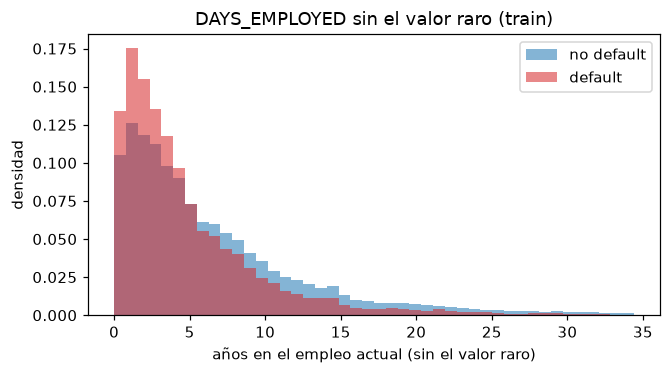

In [35]:
anios = -X.loc[~raro, "DAYS_EMPLOYED"] / 365  # sacamos el valor: años de empleo
fig, ax = plt.subplots(figsize=(6.2, 3.5))
bins = np.linspace(0, anios.quantile(0.995), 45)
for clase, color in COLORES.items():
    ax.hist(
        anios[etiqueta[~raro] == clase],
        bins=bins,
        density=True,
        alpha=0.55,
        color=color,
        label=clase,
    )
ax.set_xlabel("años en el empleo actual (sin el valor raro)")
ax.set_ylabel("densidad")
ax.set_title("DAYS_EMPLOYED sin el valor raro (train)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_eda_hc_days_employed.png")
plt.show()

In [36]:
print("AMT_INCOME_TOTAL (ingreso):")
print(X["AMT_INCOME_TOTAL"].describe(percentiles=[0.5, 0.99, 0.999]).to_string())

xna = {c: int((X[c] == "XNA").sum()) for c in cols_cat}
xna = {c: k for c, k in xna.items() if k > 0}
print("\nCategorías 'XNA' por columna:", xna if xna else "ninguna")

AMT_INCOME_TOTAL (ingreso):
count       184,506.000
mean        169,145.324
std         293,667.102
min          25,650.000
50%         148,500.000
99%         472,500.000
99.9%       900,000.000
max     117,000,000.000

Categorías 'XNA' por columna: {'CODE_GENDER': 2, 'ORGANIZATION_TYPE': 33269}


## 6. Tasa de default por grupos y señal de cada variable

Nos interesa para analizar los diferentes grupos de clientes, ademas de identificar que variables numéricas ordenan mejor a los que no cumplen. También vamos a repetir el mismo AUC de una sola variable que en ULB.

- 0,5 = no separa nada 
- lejos de 0,5 = separa más 

Para cada variable usamos solo las filas donde el dato está.

In [37]:
for c in ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE"]:
    t = y.groupby(X[c]).agg(filas="size", tasa_default="mean")
    t["tasa_default"] *= 100
    print(f"\n{c} (tasa de default en %):")
    display(t.sort_values("tasa_default", ascending=False))


NAME_CONTRACT_TYPE (tasa de default en %):


,filas,tasa_default
NAME_CONTRACT_TYPE,,
Cash loans,167076,8.343
Revolving loans,17430,5.485



CODE_GENDER (tasa de default en %):


,filas,tasa_default
CODE_GENDER,,
M,62751,10.154
F,121753,7.000
XNA,2,0.000



NAME_INCOME_TYPE (tasa de default en %):


,filas,tasa_default
NAME_INCOME_TYPE,,
Maternity leave,2,50.000
Unemployed,12,33.333
Working,95382,9.600
Commercial associate,42739,7.469
State servant,13094,5.758
Pensioner,33263,5.372
Businessman,4,0.000
Student,10,0.000



NAME_EDUCATION_TYPE (tasa de default en %):


,filas,tasa_default
NAME_EDUCATION_TYPE,,
Lower secondary,2262,11.008
Secondary / secondary special,130942,8.923
Incomplete higher,6196,8.280
Higher education,45020,5.438
Academic degree,86,1.163


,AUC (1 variable),% de filas con dato,"distancia a 0,5"
EXT_SOURCE_3,0.321,80.142,0.179
EXT_SOURCE_1,0.332,43.587,0.168
EXT_SOURCE_2,0.345,99.784,0.155
DAYS_BIRTH,0.584,100.000,0.084
OWN_CAR_AGE,0.559,33.970,0.059
DAYS_LAST_PHONE_CHANGE,0.559,100.000,0.059
DAYS_ID_PUBLISH,0.555,100.000,0.055
FLOORSMAX_AVG,0.449,50.357,0.051
REGION_RATING_CLIENT_W_CITY,0.550,100.000,0.050
FLOORSMAX_MEDI,0.450,50.357,0.050


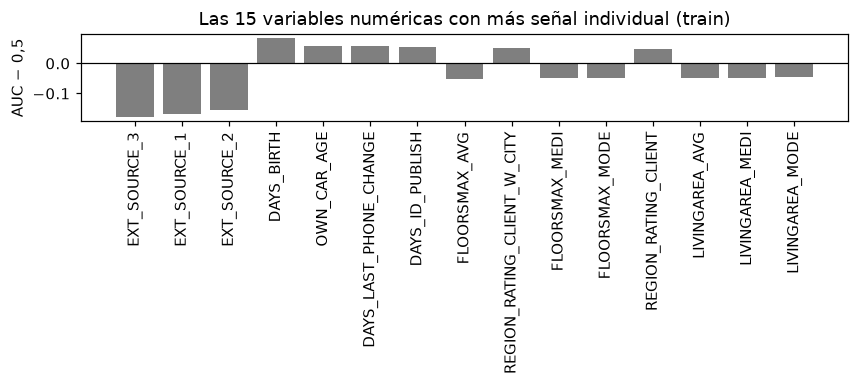

In [38]:
auc_uni, cobertura = {}, {}
for c in cols_num:
    ok = X[c].notna()
    if ok.sum() < 1_000 or X.loc[ok, c].nunique() < 2 or y[ok].nunique() < 2:
        continue
    auc_uni[c] = roc_auc_score(y[ok], X.loc[ok, c])
    cobertura[c] = 100 * ok.mean()

senal = pd.DataFrame(
    {"AUC (1 variable)": pd.Series(auc_uni), "% de filas con dato": pd.Series(cobertura)}
)
senal["distancia a 0,5"] = (senal["AUC (1 variable)"] - 0.5).abs()
senal = senal.sort_values("distancia a 0,5", ascending=False)
display(senal.head(10))

top15 = senal.head(15)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(top15.index, top15["AUC (1 variable)"] - 0.5, color="tab:gray")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("AUC − 0,5")
ax.set_title("Las 15 variables numéricas con más señal individual (train)")
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_eda_hc_auc.png")
plt.show()

Los tres EXT_SOURCE dan 0,321 / 0,332 / 0,345. Después viene DAYS_BIRTH con 0,584 y el resto queda en 0,55–0,56. La señal individual es mucho más débil que las variables analizadas en el dataset de ULB, así que el rendimiento sale de combinar muchas variables.

## 7. Duplicados

In [39]:
h = row_hashes(X)
n_dup = int(pd.Series(h).duplicated().sum())
print(f"Filas repetidas en train: {n_dup}")

Filas repetidas en train: 0
